# Alternative Evaluation Strategy (New)

This notebook implements an alternative evaluation strategy for LambdaG authorship verification using the new external packages:

1. **Size-based sampling**: Question texts are sampled to approximately 1000 tokens (using `chunk_works` to split training works into ~1000-token chunks)
2. **Balanced tests**: 200 correct tests and 200 incorrect tests
3. **Uncorrected scores**: LogisticRegression is fitted on uncorrected scores (as recommended by lambdag package author)

After initial run, we may identify problematic works (if any) to exclude from correct tests in future runs.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ray
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import joblib

from sentence_corpora import TwoLevelCorpus
from sentence_corpora.lambdag import LambdaGAV

import mpl_fontkit as fk

# Set up Roboto Condensed font
fk.install("Roboto Condensed")

# Set seaborn theme with Roboto Condensed
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 300,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    },
)

Font name: `Roboto Condensed`


In [3]:
# Load corpus
train_corpus = TwoLevelCorpus.from_pickle("train_corpus.pkl")

# Chunk works into ~1000-token pieces
train_chunked = train_corpus.chunk(1000)

# Get list of all unique (author, work) pairs from the chunked training set
all_pairs = sorted({(s.author, s.work) for s in train_chunked})
all_authors = sorted({p[0] for p in all_pairs})
print(f"Total (author, work) pairs in chunked train: {len(all_pairs)}")
print(f"Total authors in train: {len(all_authors)}")

# Target token count is approximately 1000 (each chunk is already ~1000 tokens)
TARGET_TOKENS = 1000
print(f"Using target token count: ~{TARGET_TOKENS} (one chunked work per test)")

Total (author, work) pairs in chunked train: 567
Total authors in train: 40
Using target token count: ~1000 (one chunked work per test)


In [4]:
# Define the evaluation function for Ray. Smallest author corpus in the train is about 3500 tokens,
# so we will use a K size of 2000 so that all 'correct' tests should be doable. (1000 for Q and 2000
# for K)
# Initialize Ray (automatically detects available CPUs)
ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")


@ray.remote
def run_single_evaluation(
    seed: int,
    chosen_author: str,
    chosen_work: str,
    known_author: str,
):
    """Run a single AV evaluation using a ~1000-token chunked work as unknown.

    Uses LambdaGAV which automatically infers the verification level ("author"
    for TwoLevelCorpus) from the corpus hierarchy.
    """
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Build q_corpus: the single chunked work (~1000 tokens)
    q_sentences = [
        s for s in train_chunked if s.author == chosen_author and s.work == chosen_work
    ]
    q_corpus = TwoLevelCorpus(q_sentences, levels=["author", "work"])

    # Build kr_corpus: all chunked training sentences EXCEPT the ones in q_corpus.
    kr_sentences = [
        s
        for s in train_chunked
        if not (s.author == chosen_author and s.work == chosen_work)
    ]
    kr_corpus = TwoLevelCorpus(kr_sentences, levels=["author", "work"])

    # Run AV problem
    result = av.run_single_av_problem(
        known_entity=known_author,
        q_corpus=q_corpus,
        kr_corpus=kr_corpus,
        known_tokens=2000,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    # Determine if correct
    is_correct = known_author == chosen_author

    return {
        "type": "correct" if is_correct else "incorrect",
        "author_known": known_author,
        "author_unknown": chosen_author,
        "work": chosen_work,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "n_known": result.get("known_sentences_used", 0),
        "n_reference": result.get("reference_sentences_used", 0),
        "n_unknown": result.get("unknown_sentences_used", 0),
        "unknown_tokens": result.get("unknown_tokens_used", 0),
        "error": result.get("error", None),
    }

2026-09-03 09:36:36,493	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


/opt/anaconda3/lib/python3.11/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


In [5]:
# Create evaluation tasks: 200 correct tests and 200 incorrect tests
print("Creating evaluation tasks...")
print("=" * 60)

# Create a master RNG for generating seeds
master_rng = np.random.default_rng(42)

# For now, we exclude no works from correct tests (but we can add a list if we find problematic works)
problematic_works = set()
pairs_for_correct = sorted([p for p in all_pairs if p[1] not in problematic_works])
print(
    f"Total pairs (excluding problematic works for correct tests): {len(pairs_for_correct)}"
)
print(f"Original pairs: {len(all_pairs)}")

# Select 400 works for correct tests (sample with replacement, excluding problematic works)
selected_indices = master_rng.choice(len(pairs_for_correct), size=400, replace=True)
selected_pairs = [pairs_for_correct[i] for i in selected_indices]

# Prepare all Ray tasks
tasks = []

# 1. CORRECT runs: 400 runs, one per selected work (no problematic works)
for chosen_author, chosen_work in selected_pairs:
    seed = master_rng.integers(0, 2**32 - 1)
    tasks.append(
        run_single_evaluation.remote(
            seed,
            chosen_author,
            chosen_work,
            chosen_author,  # Correct: known = author of work
        )
    )

# Select 400 works for incorrect tests (sample with replacement, including problematic works)
selected_indices = master_rng.choice(len(all_pairs), size=400, replace=True)
selected_pairs = [all_pairs[i] for i in selected_indices]

# 2. INCORRECT runs: 400 runs
# For each selected work, pick a random different author as the known author
for chosen_author, chosen_work in selected_pairs:
    # Get other authors
    other_authors = sorted([a for a in all_authors if a != chosen_author])
    # Pick one at random
    wrong_author = master_rng.choice(other_authors)

    seed = master_rng.integers(0, 2**32 - 1)
    tasks.append(
        run_single_evaluation.remote(
            seed,
            chosen_author,
            chosen_work,
            wrong_author,
        )
    )

print(f"Prepared {len(tasks)} tasks:")
print(
    f"  - 400 correct runs (excluding problematic works: {problematic_works if problematic_works else 'none'})"
)
print(f"  - 400 incorrect runs (all works allowed)")
print(f"  - Total authors: {len(all_authors)}")

Creating evaluation tasks...
Total pairs (excluding problematic works for correct tests): 567
Original pairs: 567
Prepared 800 tasks:
  - 400 correct runs (excluding problematic works: none)
  - 400 incorrect runs (all works allowed)
  - Total authors: 40


In [6]:
# Execute all tasks in parallel with progress bar
print("\nExecuting tasks in parallel...")
results = []

for _ in tqdm(range(len(tasks)), desc="Evaluations"):
    ready, _ = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    results.append(result)
    tasks.remove(ready[0])

print(f"✓ Completed {len(results)} evaluations")
ray.shutdown()


Executing tasks in parallel...


Evaluations:   0%|                                     | 0/800 [00:00<?, ?it/s](pid=2336) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=2336)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=2336) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=2336)   from pandas.core import (
Evaluations: 100%|██████████████████████████▉| 799/800 [05:09<00:00,  2.04it/s](pid=2337) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see h

✓ Completed 800 evaluations


In [7]:
# Convert to DataFrame and analyze
df = pd.DataFrame(results)

# Check for errors
errors = df[df["error"].notna()]
if len(errors) > 0:
    print(f"⚠ {len(errors)} evaluations returned errors:")
    print(
        errors[["type", "author_known", "author_unknown", "work", "error"]].to_string()
    )

print(
    f"\n=== Statistics by Author (Correct runs, n={len(df[(df['type']=='correct') & (df['error'].isna())])}) ==="
)
correct_df = df[(df["type"] == "correct") & (df["error"].isna())]
if len(correct_df) > 0:
    author_stats = correct_df.groupby("author_unknown")["corrected_score_hapax"].agg(
        ["count", "mean", "std"]
    )
    print(author_stats)

print(
    f"\n=== Statistics by Author Pair (Incorrect runs, n={len(df[(df['type']=='incorrect') & (df['error'].isna())])}) ==="
)
incorrect_df = df[(df["type"] == "incorrect") & (df["error"].isna())]
if len(incorrect_df) > 0:
    pair_stats = incorrect_df.groupby(["author_known", "author_unknown"])[
        "corrected_score_hapax"
    ].agg(["count", "mean", "std"])
    print(pair_stats)

# Summary statistics of unknown token sizes (q_corpus sizes)
print("\n=== Q-corpus Token Size Statistics ===")
valid = df[df["error"].isna()]
for test_type in ["correct", "incorrect"]:
    subset = valid[valid["type"] == test_type]
    if len(subset) > 0:
        tokens = subset["unknown_tokens"]
        print(f"\n{test_type.capitalize()} tests (n={len(subset)}):")
        print(f"  Mean:   {tokens.mean():.1f}")
        print(f"  Median: {tokens.median():.1f}")
        print(f"  Min:    {tokens.min()}")
        print(f"  Max:    {tokens.max()}")
        print(f"  Std:    {tokens.std():.1f}")
        # Count how many are below target
        below = (tokens < TARGET_TOKENS).sum()
        print(f"  Below {TARGET_TOKENS}: {below} ({100*below/len(subset):.1f}%)")

# Per-author q-corpus size summary
print("\n=== Q-corpus Token Sizes by Author (Correct runs) ===")
if len(correct_df) > 0:
    author_tokens = correct_df.groupby("author_unknown")["unknown_tokens"].agg(
        ["count", "mean", "min", "max"]
    )
    print(author_tokens.to_string())

# Save results to CSV
output_path = "av_evaluation_results.csv"
df.to_csv(output_path, index=False)
print(f"\n✓ Saved results to {output_path}")


=== Statistics by Author (Correct runs, n=400) ===
                count       mean       std
author_unknown                            
AI                 13  14.648674  4.917906
AeC                25   9.565994  3.787673
AeP                 9   2.608145  5.006382
B                   2  10.584486  0.810005
BC                 14  35.397248  7.052547
DC                 12  18.826567  6.048117
E                   4  14.337734  5.105981
FB                 12  12.993029  2.778966
GAp                 7  12.841441  3.496820
GAr                22   9.609908  3.610751
GB                 11  36.516004  8.399043
GC                 17   8.032951  3.145395
GM                  6  18.700945  2.646861
GP                 20  11.613206  4.803259
GVS                13  17.083678  4.039790
GiP                12   9.865697  4.955367
H                   1  12.728361       NaN
HA                 11  14.165054  4.820683
HP                  6  17.489707  2.789879
IDG                20  25.591016  4.619131
IH

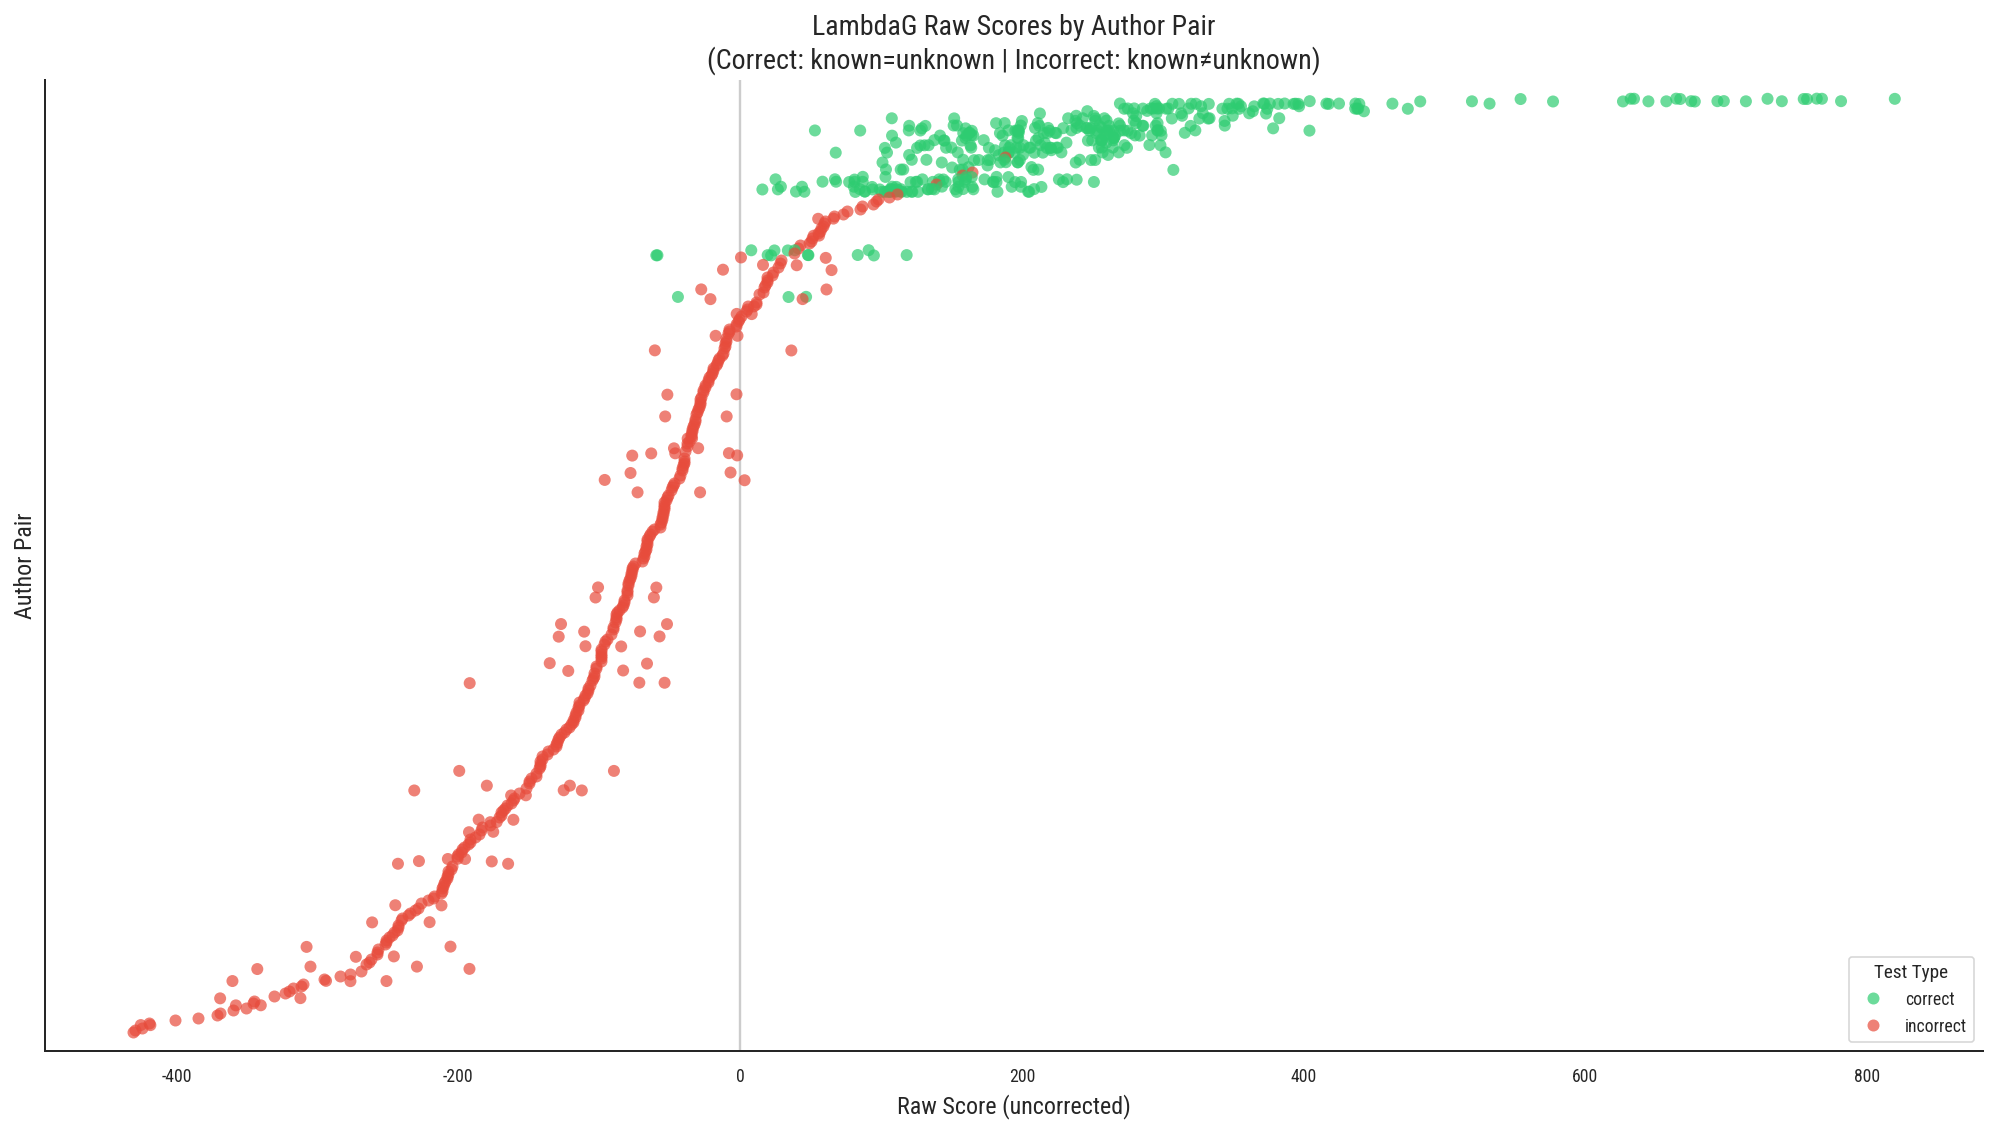

In [8]:
# Dot plot: raw scores by author pair
fig, ax = plt.subplots(figsize=(14, 8), dpi=144)

# Create pair labels for incorrect runs
df_plot = df.copy()
df_plot["pair_label"] = df_plot.apply(
    lambda row: (
        f"{row['author_known']} vs {row['author_unknown']}"
        if row["type"] == "incorrect"
        else f"{row['author_known']} vs {row['author_unknown']} (correct)"
    ),
    axis=1,
)

# Sort by type then by mean raw score
order = (
    df_plot.groupby("pair_label")["score"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

# Use stripplot with dots for each data point, colored by correct/incorrect
sns.stripplot(
    data=df_plot,
    x="score",
    y="pair_label",
    hue="type",
    palette={"correct": "#2ecc71", "incorrect": "#e74c3c"},
    order=order,
    size=6,
    jitter=True,
    alpha=0.7,
    ax=ax,
)
sns.despine()
ax.axvline(x=0, color="black", linestyle="-", alpha=0.2)
ax.set_title(
    "LambdaG Raw Scores by Author Pair\n(Correct: known=unknown | Incorrect: known≠unknown)",
    fontsize=14,
)
ax.set_xlabel("Raw Score (uncorrected)", fontsize=12)
ax.set_ylabel("Author Pair", fontsize=12)
ax.legend(title="Test Type")
ax.margins(y=0.02)  # Add small vertical margins
sns.move_legend(ax, "lower right")
plt.yticks([])  # Hide y-axis ticks
plt.tight_layout()
plt.show()

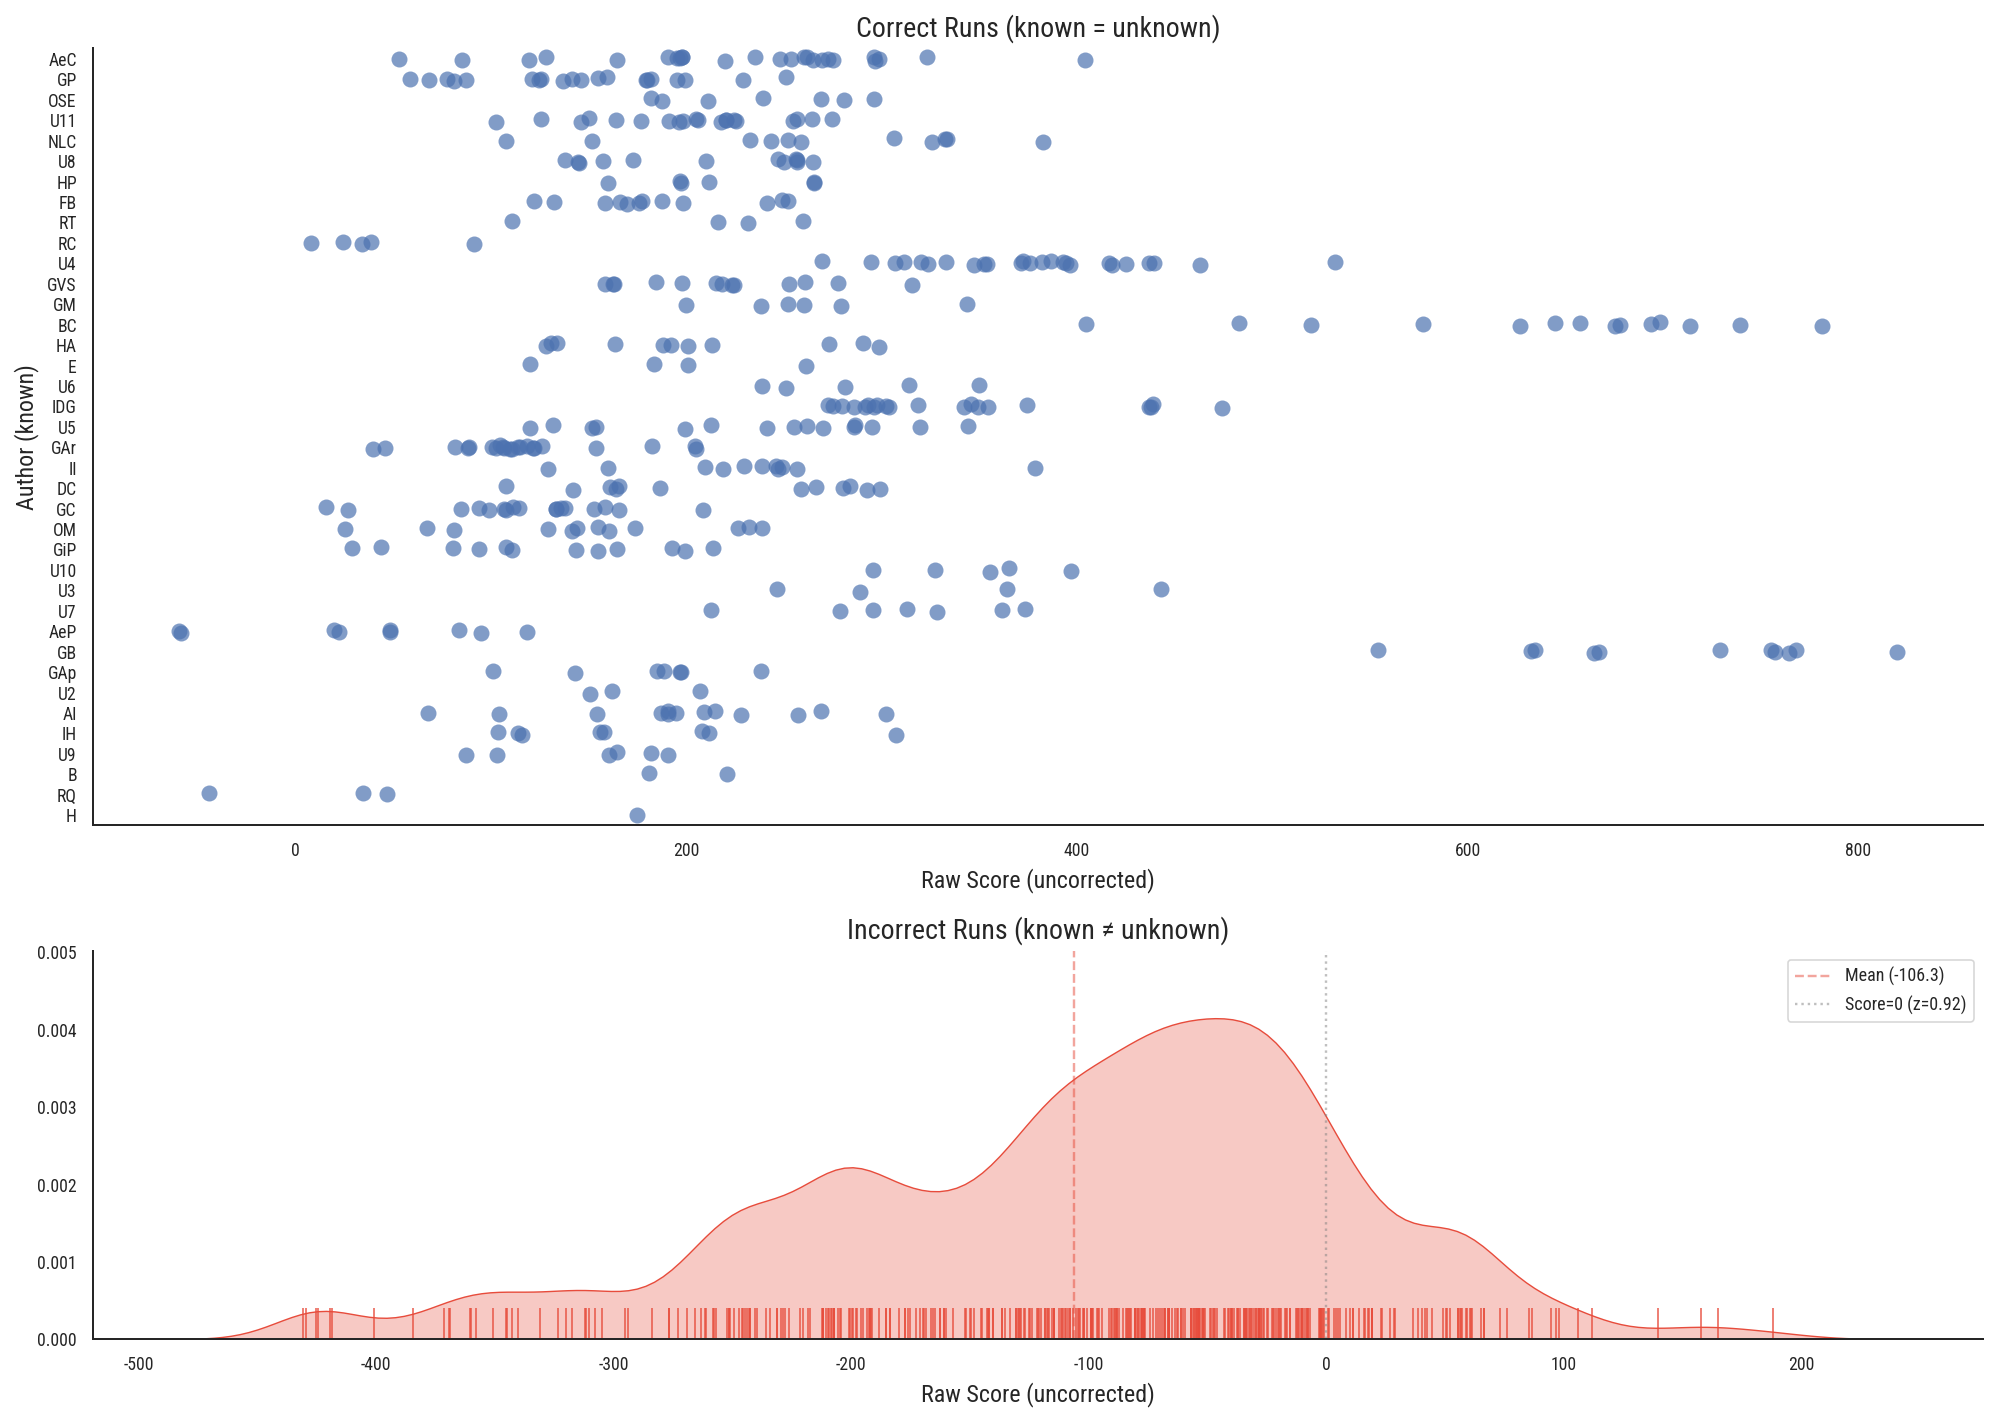

In [9]:
# Separate dot plots for correct vs incorrect: raw scores
fig, axes = plt.subplots(
    2, 1, figsize=(14, 10), dpi=144, gridspec_kw={"height_ratios": [2, 1]}
)

# Correct runs
correct_data = df[df["type"] == "correct"]
sns.stripplot(
    data=correct_data,
    y="author_unknown",
    x="score",
    size=8,
    jitter=True,
    alpha=0.7,
    ax=axes[0],
)
sns.despine(ax=axes[0])
axes[0].set_title("Correct Runs (known = unknown)", fontsize=14)
axes[0].set_xlabel("Raw Score (uncorrected)", fontsize=12)
axes[0].set_ylabel("Author (known)", fontsize=12)

# Incorrect runs: filled KDE plot with rug plot overlay
incorrect_data = df[df["type"] == "incorrect"]
sns.kdeplot(
    data=incorrect_data,
    x="score",
    color="#e74c3c",
    linewidth=0.7,
    fill=True,
    alpha=0.3,
    ax=axes[1],
    bw_adjust=0.5,
)
sns.rugplot(
    data=incorrect_data,
    x="score",
    color="#e74c3c",
    height=0.08,
    linewidth=1,
    alpha=0.7,
    ax=axes[1],
)
sns.despine(ax=axes[1])
# Add vline for mean incorrect score
mean_incorrect = incorrect_data["score"].mean()
std_incorrect = incorrect_data["score"].std()
axes[1].axvline(
    x=mean_incorrect,
    color="#e74c3c",
    linestyle="--",
    alpha=0.5,
    label=f"Mean ({mean_incorrect:.1f})",
)
# Add vline for score=0 with z-score annotation
if 0 >= incorrect_data["score"].min() and 0 <= incorrect_data["score"].max():
    z_at_zero = (0 - mean_incorrect) / std_incorrect if std_incorrect > 0 else 0
    axes[1].axvline(
        x=0,
        color="gray",
        linestyle=":",
        alpha=0.5,
        label=f"Score=0 (z={z_at_zero:.2f})",
    )
axes[1].legend(fontsize=9)
axes[1].set_title("Incorrect Runs (known ≠ unknown)", fontsize=14)
axes[1].set_xlabel("Raw Score (uncorrected)", fontsize=12)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


LOGISTIC REGRESSION ON SCORES

Label shape: (800,)
Class distribution: [400 400]

MODEL: UNCORRECTED score

Feature shape: (800, 1)

Model coefficients: 0.036134
Model intercept: -2.132496

=== Classification Report ===
              precision    recall  f1-score   support

   incorrect       0.95      0.95      0.95       400
     correct       0.95      0.94      0.95       400

    accuracy                           0.95       800
   macro avg       0.95      0.95      0.95       800
weighted avg       0.95      0.95      0.95       800


=== Score Thresholds ===
Mean score (correct): 238.14
Mean score (incorrect): -106.28

✓ Model saved to logistic_regression_model_uncorrected.pkl


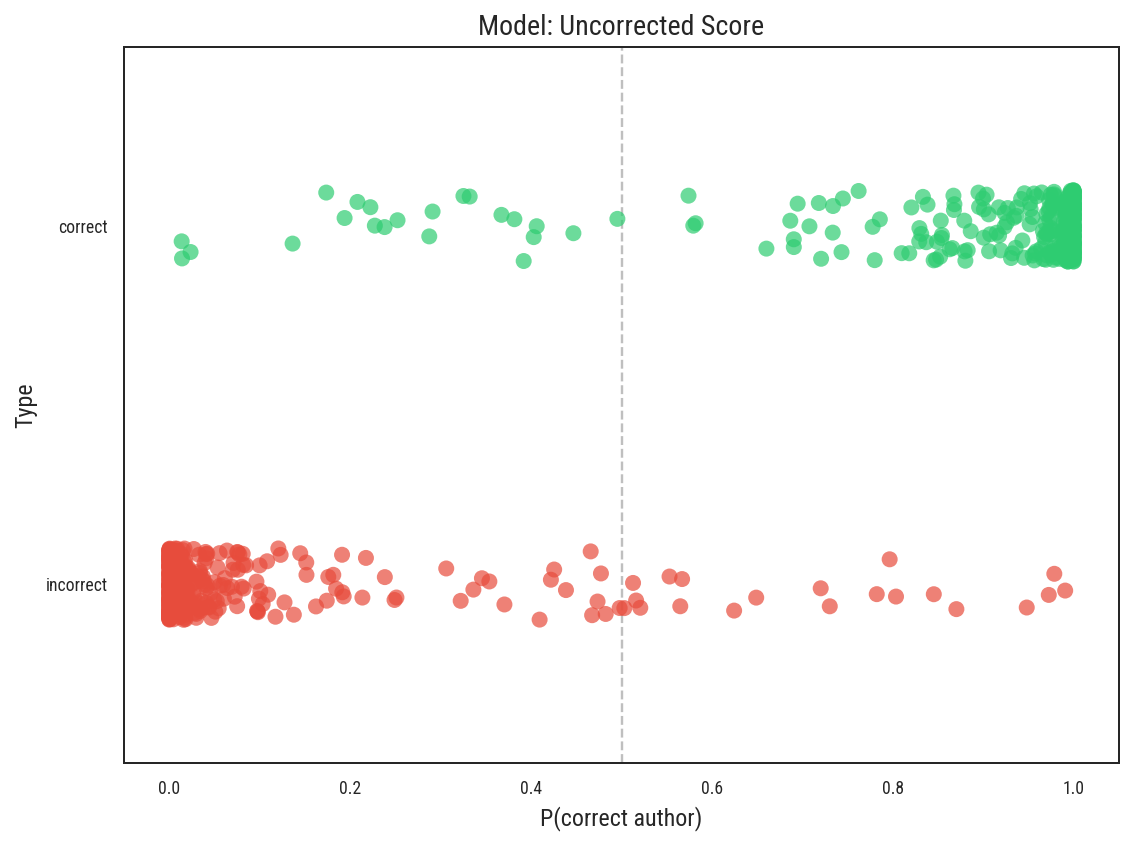


=== Probability Statistics (uncorrected model) ===
           count      mean       std           min       max
type                                                        
correct      400  0.925404  0.177796  1.362248e-02  1.000000
incorrect    400  0.074594  0.177241  2.066230e-08  0.990615


In [10]:
# Fit LogisticRegression model on scores

print("\n" + "=" * 80)
print("LOGISTIC REGRESSION ON SCORES")
print("=" * 80)

# Create label array y: 1 for correct author, 0 for incorrect
y = (df["type"] == "correct").astype(int).values

print(f"\nLabel shape: {y.shape}")
print(f"Class distribution: {np.bincount(y)}")

# Model: UNCORRECTED score
print("\n" + "=" * 80)
print("MODEL: UNCORRECTED score")
print("=" * 80)

X_uncorrected = df["score"].values.reshape(-1, 1)
print(f"\nFeature shape: {X_uncorrected.shape}")

model_uncorrected = LogisticRegression()
model_uncorrected.fit(X_uncorrected, y)

print(f"\nModel coefficients: {model_uncorrected.coef_[0][0]:.6f}")
print(f"Model intercept: {model_uncorrected.intercept_[0]:.6f}")

y_pred_uncorrected = model_uncorrected.predict(X_uncorrected)
y_prob_uncorrected = model_uncorrected.predict_proba(X_uncorrected)[:, 1]

print("\n=== Classification Report ===")
print(
    classification_report(y, y_pred_uncorrected, target_names=["incorrect", "correct"])
)

print("\n=== Score Thresholds ===")
print(f"Mean score (correct): {df[df['type']=='correct']['score'].mean():.2f}")
print(f"Mean score (incorrect): {df[df['type']=='incorrect']['score'].mean():.2f}")

# Save the model
joblib.dump(model_uncorrected, "logistic_regression_model_uncorrected.pkl")
print("\n✓ Model saved to logistic_regression_model_uncorrected.pkl")

# Add predictions to DataFrame
df["predicted_uncorrected"] = y_pred_uncorrected
df["probability_uncorrected"] = y_prob_uncorrected

# Visualize predicted probabilities
fig, ax = plt.subplots(1, 1, figsize=(8, 6), dpi=144)

sns.stripplot(
    data=df,
    x="probability_uncorrected",
    y="type",
    hue="type",
    palette={
        "correct": "#2ecc71",
        "incorrect": "#e74c3c",
    },
    size=8,
    jitter=True,
    alpha=0.7,
    legend=False,
    ax=ax,
)
ax.set_title("Model: Uncorrected Score", fontsize=14)
ax.set_xlabel("P(correct author)", fontsize=12)
ax.set_ylabel("Type", fontsize=12)
ax.axvline(x=0.5, color="gray", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Summary statistics
print("\n=== Probability Statistics (uncorrected model) ===")
print(
    df.groupby("type")["probability_uncorrected"].agg(
        ["count", "mean", "std", "min", "max"]
    )
)